### Basic - Temperature Conversion Workflow

In [7]:
from langgraph.graph import StateGraph, START, END 
from typing import TypedDict

#### Define State

In [2]:
class TemperatureState(TypedDict):
    temp_celsius: float
    temp_fahrenheit: float

#### Convert Temperature Function (First Node)

In [4]:
def convert_temp(state: TemperatureState) -> TemperatureState:
    celsius = state['temp_celsius']
    fahrenheit = (celsius * 9/5) + 32
    state['temp_fahrenheit'] = round(fahrenheit, 2)

    return state

#### Define and Compile Graph

In [8]:
#define your graph
graph = StateGraph(TemperatureState) # StateGraph provide our State to nodes automatically

#add nodes to the graph
graph.add_node('convert_temp', convert_temp) #START AND END Nodes are dummy nodes we dont need to add seperately

#add edges to the graph
graph.add_edge(START, 'convert_temp')
graph.add_edge('convert_temp', END)

#compile the graph
workflow = graph.compile()


#### Execute Graph

In [9]:
initial_state = {'temp_celsius': 28.5}
final_state = workflow.invoke(initial_state)
print(final_state)

{'temp_celsius': 28.5, 'temp_fahrenheit': 83.3}


#### Visualize LangGraph

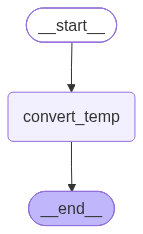

In [10]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

#### Add Weather Status

In [11]:
class TemperatureState(TypedDict):
    temp_celsius: float
    temp_fahrenheit: float
    weather_status: str

In [12]:
def convert_temp(state: TemperatureState) -> TemperatureState:
    celsius = state['temp_celsius']
    fahrenheit = (celsius * 9/5) + 32
    state['temp_fahrenheit'] = round(fahrenheit, 2)

    return state

def label_weather(state: TemperatureState) -> TemperatureState:
    fahrenheit = state['temp_fahrenheit']
    if fahrenheit < 50:
        state['weather_status'] = 'Cold'
    elif 50 <= fahrenheit <= 77:
        state['weather_status'] = 'Mild'
    elif 77 <= fahrenheit < 95:
        state['weather_status'] = 'Hot'
    else:
        state['weather_status'] = 'Heat Wave' 
    return state

In [13]:
#define your graph
graph = StateGraph(TemperatureState) # StateGraph provide our State to nodes automatically

#add nodes to the graph
graph.add_node('convert_temp', convert_temp) #START AND END Nodes are dummy nodes we dont need to add seperately
graph.add_node('label_weather', label_weather)
#add edges to the graph
graph.add_edge(START, 'convert_temp')
graph.add_edge('convert_temp', 'label_weather')
graph.add_edge('label_weather', END)

#compile the graph
workflow = graph.compile()


In [14]:
initial_state = {'temp_celsius': 45}
final_state = workflow.invoke(initial_state)
print(final_state)

{'temp_celsius': 45, 'temp_fahrenheit': 113.0, 'weather_status': 'Heat Wave'}


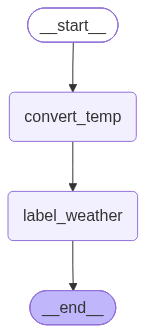

In [15]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())